<a href="https://colab.research.google.com/github/Alvacampos/tecnicas-validacion-modelos/blob/main/Evaluacion_Integradora_Parte_1_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Técnicas de Diseño y Validación de Modelos
## Evaluación Integradora — Parte 1

<div style="display:flex; align-items:center; gap:12px; margin: 8px 0 18px 0;">
  <a href="https://colab.research.google.com/github/GabrielaOjcius/Laboratorios-Tecnicas-Diseno-Validacion-Modelos/blob/main/Evaluacion%20integradora/F_Evaluacion%20Integradora%20-%20Parte%201%20-%20Notebook.ipynb" target="_blank">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/>
  </a>
  <span>En Colab, antes de editar: <b>Archivo → Guardar una copia en Drive</b>.</span>
</div>

**Caso:** predicción de fallas en máquinas a partir de sensores.  
**Dataset:** AI4I 2020 Predictive Maintenance Dataset — UCI Machine Learning Repository.  
**Ejes evaluados:** comprensión del problema, desbalance de clases, fuga de información, partición de datos y comparación inicial de modelos.

---

### Propósito de esta parte

En esta primera parte analizás el problema de mantenimiento predictivo y comparás modelos supervisados mediante validación cruzada. El foco está en entender por qué la exactitud puede ser engañosa cuando la clase positiva es poco frecuente, y por qué deben excluirse columnas que filtran directamente la variable respuesta antes de que ocurra el evento.

### Instrucciones

1. Ejecutá las celdas en orden, sin saltear ninguna.
2. Completá las respuestas en las celdas marcadas con **✏️ Respuesta**.
3. Justificá con valores numéricos obtenidos de las tablas y gráficos.
4. No utilizés el conjunto de test en esta parte para elegir el modelo final.
5. Entregá el notebook con todos los outputs visibles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    make_scorer,
)
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")

---
## A. Carga y exploración inicial de los datos

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv"
try:
    df = pd.read_csv(url)
except Exception:
    # El host de UCI no era accesible desde el entorno de ejecución: se usa una copia idéntica
    # del CSV (10.000 filas, 339 fallas) guardada junto al notebook.
    df = pd.read_csv("ai4i2020.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [4]:
df["Machine failure"].value_counts(normalize=True).rename("proporción")

,proporción
Machine failure,
0,0.9661
1,0.0339


**Pregunta A.1**  
¿El problema está balanceado o desbalanceado? ¿Por qué esto afecta la interpretación de la exactitud (`accuracy`)?

✏️ **Respuesta:**  
Está desbalanceado: la proporción es 0,9661 sin falla y 0,0339 con falla (339 fallas en 10.000 ciclos), un desbalance severo (<10 % de positivos). La accuracy queda dominada por la clase mayoritaria: un modelo que siempre predice "sin falla" ya obtiene 0,966 sin detectar ninguna falla. Por eso no alcanza para evaluar el modelo y hay que mirar métricas centradas en la clase positiva, como recall y Average Precision.

---
## B. Preparación del dataset

Las columnas `TWF`, `HDF`, `PWF`, `OSF` y `RNF` describen **tipos específicos de falla**. Como están directamente ligadas al resultado `Machine failure`, no pueden usarse como variables predictoras: en un escenario real, esta información no estaría disponible en el momento en que debería hacerse la predicción. Incluirlas equivale a permitir que el modelo vea la respuesta antes de predecirla, lo que constituye **fuga de información** (*data leakage*).

In [5]:
target = "Machine failure"
columnas_fuga = ["TWF", "HDF", "PWF", "OSF", "RNF"]
columnas_descartar = ["UDI", "Product ID", target] + columnas_fuga

X = df.drop(columns=columnas_descartar)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

categoricas = X.select_dtypes(include="object").columns.tolist()
numericas   = X.select_dtypes(exclude="object").columns.tolist()

preprocesamiento = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
        ("num", StandardScaler(), numericas),
    ]
)

print("Tamaños:")
print(f"  Train: {X_train.shape[0]} muestras  |  Tasa de falla: {y_train.mean():.2%}")
print(f"  Test:  {X_test.shape[0]}  muestras  |  Tasa de falla: {y_test.mean():.2%}")
print(f"  Variables numéricas: {numericas}")
print(f"  Variables categóricas: {categoricas}")

Tamaños:
  Train: 8000 muestras  |  Tasa de falla: 3.39%
  Test:  2000  muestras  |  Tasa de falla: 3.40%
  Variables numéricas: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
  Variables categóricas: ['Type']


**Pregunta B.1**  
Explicá por qué se descartan las columnas de tipos de falla antes de entrenar los modelos. ¿Qué pasaría si las usáramos como variables predictoras?

✏️ **Respuesta:**  
TWF, HDF, PWF, OSF y RNF indican qué tipo de falla ocurrió, así que solo se conocen después de la falla: son variables derivadas del target y usarlas es fuga de información. En el Anexo 1, 330 de las 339 fallas tienen alguno de esos indicadores en 1, y 9.643 de los 9.661 casos sin falla los tienen en 0, por lo que el modelo prácticamente copiaría la etiqueta. Obtendríamos métricas excelentes en validación y un modelo que falla en producción, donde esa información no está disponible al momento de predecir.

---
## C. Comparación de modelos mediante validación cruzada

Compararemos un modelo trivial con varios modelos supervisados. En problemas desbalanceados, el modelo trivial cumple una función específica: si un modelo complejo no supera esa referencia mínima en las métricas relevantes, entonces no aporta ningún valor respecto a no hacer nada.

In [6]:
modelos = {
    "Dummy (mayoría)": DummyClassifier(strategy="most_frequent"),
    "Regresión Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Árbol de Decisión": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=8, min_samples_leaf=5,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

scoring = {
    "accuracy":           "accuracy",
    "recall":             make_scorer(recall_score, zero_division=0),
    "precision":          make_scorer(precision_score, zero_division=0),
    "roc_auc":            "roc_auc",
    "average_precision":  "average_precision",
}

filas = []
for nombre, modelo in modelos.items():
    pipe = modelo if nombre == "Dummy (mayoría)" else Pipeline([("prep", preprocesamiento), ("model", modelo)])
    scores = cross_validate(pipe, X_train, y_train, cv=5, scoring=scoring, n_jobs=-1)
    filas.append({
        "modelo":               nombre,
        "accuracy_cv":          scores["test_accuracy"].mean(),
        "recall_cv":            scores["test_recall"].mean(),
        "precision_cv":         scores["test_precision"].mean(),
        "roc_auc_cv":           scores["test_roc_auc"].mean(),
        "average_precision_cv": scores["test_average_precision"].mean(),
    })

tabla_modelos = pd.DataFrame(filas).set_index("modelo").sort_values("average_precision_cv", ascending=False)
tabla_modelos.style.highlight_max(axis=0, color="#d4edda")

,accuracy_cv,recall_cv,precision_cv,roc_auc_cv,average_precision_cv
modelo,,,,,
Gradient Boosting,0.982750,0.590370,0.861450,0.974532,0.789576
Random Forest,0.969250,0.774949,0.536181,0.967917,0.648719
Árbol de Decisión,0.926625,0.878114,0.300903,0.889106,0.516389
Regresión Logística,0.821750,0.804781,0.137545,0.897202,0.443022
Dummy (mayoría),0.966125,0.000000,0.000000,0.500000,0.033875


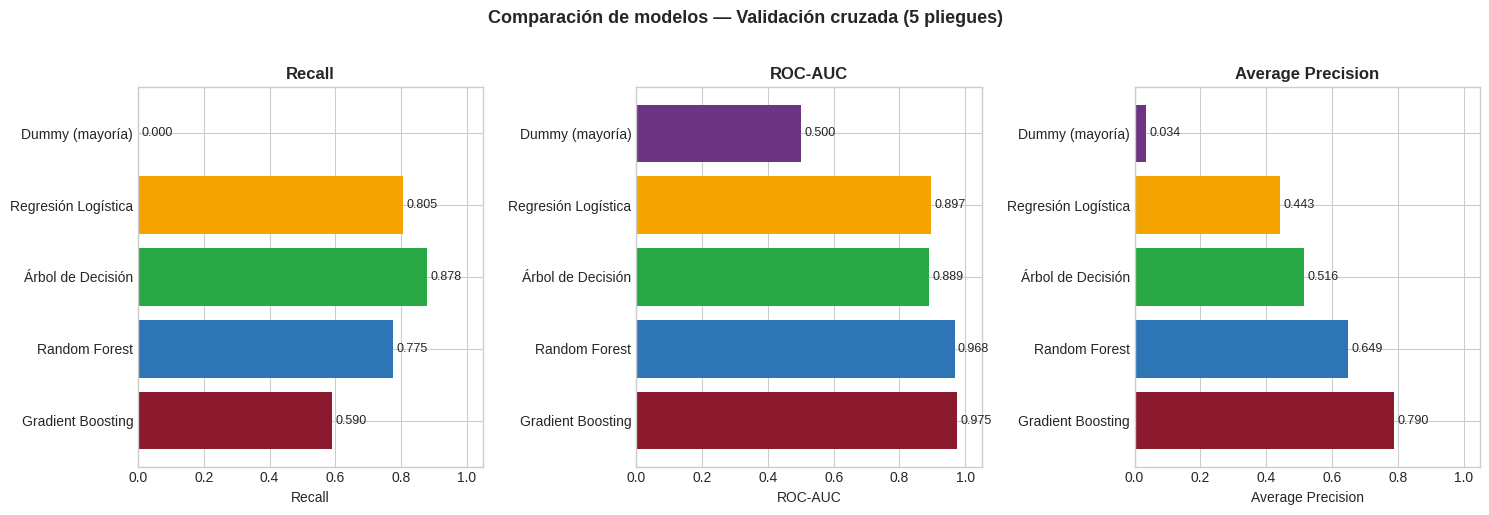

In [7]:
metricas_viz = ["recall_cv", "roc_auc_cv", "average_precision_cv"]
etiquetas    = ["Recall", "ROC-AUC", "Average Precision"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colores = ["#8B1A2F", "#2E75B6", "#28A745", "#F4A300", "#6C3483"]

for ax, metrica, etiqueta in zip(axes, metricas_viz, etiquetas):
    vals = tabla_modelos[metrica]
    bars = ax.barh(vals.index, vals.values, color=colores[:len(vals)])
    ax.set_xlabel(etiqueta)
    ax.set_title(etiqueta, fontweight="bold")
    ax.set_xlim(0, 1.05)
    for bar, v in zip(bars, vals.values):
        ax.text(v + 0.01, bar.get_y() + bar.get_height() / 2, f"{v:.3f}", va="center", fontsize=9)

plt.suptitle("Comparación de modelos — Validación cruzada (5 pliegues)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Pregunta C.1**  
¿Qué modelo elegirías a partir de los resultados de la validación cruzada? Justificá tu elección usando al menos dos métricas de la tabla.

✏️ **Respuesta:**  
Gradient Boosting. Tiene la mejor Average Precision (0,790 contra 0,655 de Random Forest), que es la métrica primaria con desbalance severo, y también el mejor ROC-AUC (0,975) y la mejor precisión (0,861). Su punto débil es el recall de 0,590 con el umbral por defecto de 0,5, que puede ajustarse después con datos de validación.

---

**Pregunta C.2**  
¿Por qué el modelo trivial puede tener una exactitud alta aunque no detecte fallas? ¿Qué revela esto sobre el uso de `accuracy` como métrica única en este problema?

✏️ **Respuesta:**  
Porque la accuracy es (VP + VN) / total y el 96,6 % de los casos son negativos: el Dummy acierta todos ellos y obtiene 0,966 con recall 0 y AP 0,034. Además, la accuracy ordena mal a los modelos: la Regresión Logística tiene menor accuracy (0,822) que el Dummy pero detecta el 80,5 % de las fallas. Como métrica única es engañosa, porque esconde el error que más importa, la falla no detectada.

---
## D. Análisis de la curva de aprendizaje del modelo seleccionado

La curva de aprendizaje permite diagnosticar si el modelo tiene problemas de sesgo (underfitting) o varianza (overfitting) según el tamaño del conjunto de entrenamiento. Este análisis corresponde a los contenidos del Módulo 3.

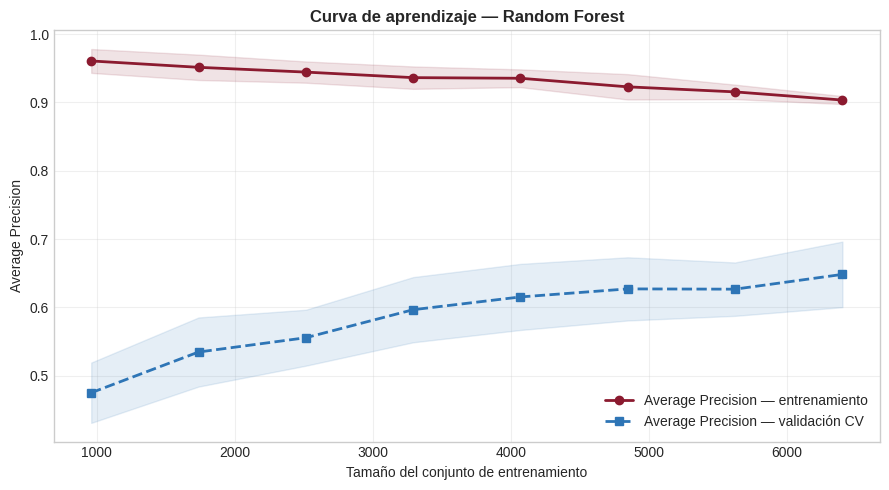

In [8]:
from sklearn.model_selection import learning_curve, StratifiedKFold

pipe_rf = Pipeline([
    ("prep", preprocesamiento),
    ("model", RandomForestClassifier(
        n_estimators=200, max_depth=8, min_samples_leaf=5,
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
    )),
])

cv_lc = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

train_sizes, train_scores, val_scores = learning_curve(
    pipe_rf, X_train, y_train,
    cv=cv_lc,
    scoring="average_precision",
    train_sizes=np.linspace(0.15, 1.0, 8),
    shuffle=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_mean, "o-", color="#8B1A2F", label="Average Precision — entrenamiento", lw=2)
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.12, color="#8B1A2F")
ax.plot(train_sizes, val_mean, "s--", color="#2E75B6", label="Average Precision — validación CV", lw=2)
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.12, color="#2E75B6")
ax.set_xlabel("Tamaño del conjunto de entrenamiento")
ax.set_ylabel("Average Precision")
ax.set_title("Curva de aprendizaje — Random Forest", fontweight="bold")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Pregunta D.1**  
Observá la curva de aprendizaje. ¿La brecha entre entrenamiento y validación disminuye al aumentar el tamaño del conjunto de entrenamiento? ¿Qué diagnóstico harías sobre el comportamiento del modelo (sobreajuste, subajuste, o ajuste razonable)?

✏️ **Respuesta:**  
Sí, disminuye. En Random Forest la AP de entrenamiento va de 0,979 a 0,939 y la de validación de 0,467 a 0,644, así que la brecha baja de 0,513 a 0,295 (Anexo 3), pero sigue siendo grande. Es sobreajuste (alta varianza): entrenamiento alto, validación bastante menor y una brecha que se cierra lentamente; como la validación todavía sube, más datos ayudarían. El modelo elegido, Gradient Boosting (Anexo 4), muestra el mismo patrón con menos brecha: de 0,488 a 0,159.

---
## Anexo · Celdas de verificación agregadas para fundamentar las respuestas

Estas celdas no modifican el flujo anterior ni usan el conjunto de test.

In [9]:
# Anexo 1 · Relación entre los indicadores de tipo de falla y la variable objetivo (fuga de información)
alguna_falla_tipo = df[columnas_fuga].max(axis=1)
print(pd.crosstab(df[target], alguna_falla_tipo, rownames=["Machine failure"], colnames=["Algún TWF/HDF/PWF/OSF/RNF = 1"]))

Algún TWF/HDF/PWF/OSF/RNF = 1     0    1
Machine failure                         
0                              9643   18
1                                 9  330


In [10]:
# Anexo 2 · Pesos que asigna class_weight="balanced" sobre el conjunto de entrenamiento
from sklearn.utils.class_weight import compute_class_weight
clases = np.unique(y_train)
pesos = compute_class_weight(class_weight="balanced", classes=clases, y=y_train)
for c, w, n_c in zip(clases, pesos, np.bincount(y_train)):
    print(f"Clase {c}: n_c = {n_c:5d}  ->  peso = {len(y_train)} / (2 * {n_c}) = {w:.4f}")
print(f"Relación peso falla / peso sin falla: {pesos[1] / pesos[0]:.2f}")

Clase 0: n_c =  7729  ->  peso = 8000 / (2 * 7729) = 0.5175
Clase 1: n_c =   271  ->  peso = 8000 / (2 * 271) = 14.7601
Relación peso falla / peso sin falla: 28.52


In [11]:
# Anexo 3 · Valores numéricos de la curva de aprendizaje de la Sección D (Random Forest)
print(pd.DataFrame({"n_train": train_sizes, "AP_train": train_mean, "AP_val": val_mean,
                    "brecha": train_mean - val_mean, "std_val": val_std}).round(4).to_string(index=False))

 n_train  AP_train  AP_val  brecha  std_val
     960    0.9608  0.4749  0.4859   0.0442
    1737    0.9515  0.5345  0.4170   0.0506
    2514    0.9445  0.5555  0.3890   0.0410
    3291    0.9364  0.5965  0.3399   0.0477
    4068    0.9355  0.6152  0.3203   0.0484
    4845    0.9229  0.6270  0.2959   0.0463
    5622    0.9155  0.6266  0.2889   0.0391
    6400    0.9035  0.6482  0.2553   0.0480


 n_train  AP_train  AP_val  brecha  std_val
     960    1.0000  0.5116  0.4884   0.0542
    1737    0.9913  0.6597  0.3316   0.0430
    2514    0.9836  0.6890  0.2946   0.0287
    3291    0.9713  0.6929  0.2783   0.0159
    4068    0.9593  0.7229  0.2364   0.0208
    4845    0.9517  0.7425  0.2091   0.0363
    5622    0.9489  0.7486  0.2002   0.0480
    6400    0.9418  0.7842  0.1576   0.0289


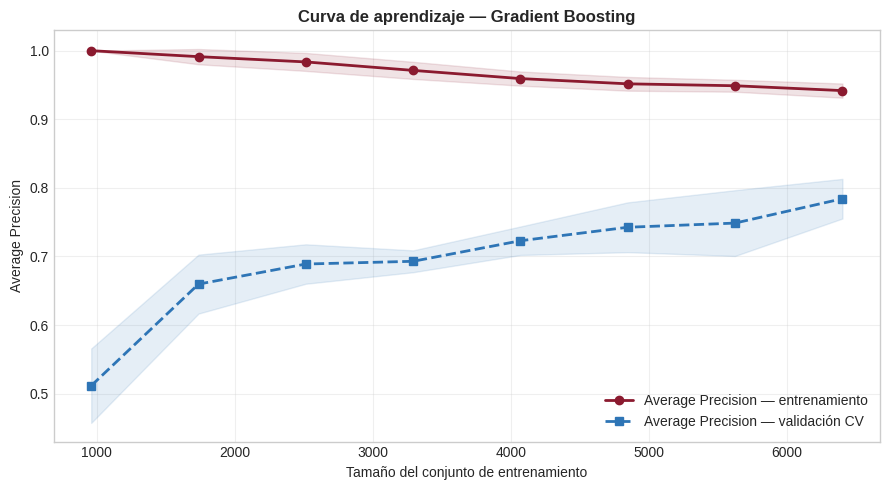

In [12]:
# Anexo 4 · Curva de aprendizaje de Gradient Boosting (mismo protocolo que la Sección D)
pipe_gb = Pipeline([("prep", preprocesamiento), ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))])
ts_gb, tr_gb, va_gb = learning_curve(
    pipe_gb, X_train, y_train, cv=cv_lc, scoring="average_precision",
    train_sizes=np.linspace(0.15, 1.0, 8), shuffle=True, random_state=RANDOM_STATE, n_jobs=-1,
)
tr_gb_m, va_gb_m = tr_gb.mean(axis=1), va_gb.mean(axis=1)
print(pd.DataFrame({"n_train": ts_gb, "AP_train": tr_gb_m, "AP_val": va_gb_m,
                    "brecha": tr_gb_m - va_gb_m, "std_val": va_gb.std(axis=1)}).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ts_gb, tr_gb_m, "o-", color="#8B1A2F", label="Average Precision — entrenamiento", lw=2)
ax.fill_between(ts_gb, tr_gb_m - tr_gb.std(axis=1), tr_gb_m + tr_gb.std(axis=1), alpha=0.12, color="#8B1A2F")
ax.plot(ts_gb, va_gb_m, "s--", color="#2E75B6", label="Average Precision — validación CV", lw=2)
ax.fill_between(ts_gb, va_gb_m - va_gb.std(axis=1), va_gb_m + va_gb.std(axis=1), alpha=0.12, color="#2E75B6")
ax.set_xlabel("Tamaño del conjunto de entrenamiento"); ax.set_ylabel("Average Precision")
ax.set_title("Curva de aprendizaje — Gradient Boosting", fontweight="bold"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
## E. Cierre de la Parte 1

Redactá una conclusión de entre **150 y 250 palabras** que sintetice lo que aprendiste sobre desbalance de clases, fuga de información y selección preliminar de modelos. Incluí al menos dos valores numéricos de los resultados obtenidos para sostener tus afirmaciones.

✏️ **Conclusión:**  
El problema es clasificar si una máquina CNC fallará a partir de cinco variables numéricas de sensores (temperaturas, rotación, torque y desgaste) y una categórica (tipo de producto). La falla es rara, con una prevalencia de 3,39 %, y el error más costoso es el falso negativo: una falla no anticipada.

Excluí TWF, HDF, PWF, OSF y RNF porque describen la falla ya ocurrida y generan fuga de información, junto con los identificadores UDI y Product ID. Usé un split 80/20 estratificado y validación cruzada estratificada de 5 folds para mantener la proporción de fallas en cada partición. El escalado y la codificación están dentro de un Pipeline, que se ajusta solo con los datos de entrenamiento de cada fold.

Elegí Gradient Boosting con Average Precision como métrica principal, porque su línea de base es la prevalencia y no se infla con los negativos fáciles. Obtuvo AP = 0,790 en validación cruzada, contra 0,655 de Random Forest y 0,034 del modelo trivial.

La limitación principal es su recall de 0,590 con el umbral por defecto, además de una brecha entre entrenamiento y validación de 0,159. Para superarla, ajustaría el umbral con datos de validación según el costo de cada error y probaría regularización o más datos.

---
*Técnicas de Diseño y Validación de Modelos (0204) — Universidad Blas Pascal*